# EDA de tiempos de cierre · NYC 311 *Noise - Residential* (2025)

**Proyecto:** NYC 311 Operational Analytics · V1
**Autor:** Junior E. Jiménez
**Datos:** `data/raw/2025-01.parquet` a `2025-12.parquet`, generados con `dataset.descargar_rango("2025-01", "2025-12")`

## Objetivo
Describir el tiempo de cierre de las solicitudes de ruido residencial de 2025, identificar diferencias por distrito, tipo de ruido y hora, y fijar las definiciones que usará V1: la partición temporal y el umbral de cierre tardío.

## Definiciones fijas del proyecto
Estas definiciones se establecen en este notebook y no cambian en el resto del proyecto.

| Concepto | Definición |
| --- | --- |
| Tiempo de cierre (`resolution_time_hours`) | `closed_date − created_date`, en horas |
| Partición | Entrenamiento: enero–agosto de 2025 · Validación: septiembre–octubre · Prueba: noviembre–diciembre (se usa una sola vez, en la semana 12) |
| Cierre tardío (`is_late`) | Tiempo de cierre mayor que el P75 de enero–agosto de 2025, redondeado a la media hora. Se calcula una vez y no se recalcula. |
| Supuesto de costo | Un cierre tardío no detectado (falso negativo) cuesta 3 veces más que una alerta innecesaria (falso positivo). Es un supuesto, no un dato; se usa en la semana 12. |

## Alcance y consideraciones
- El análisis exploratorio cubre el año completo; el umbral se calcula **solo** con enero–agosto.
- Las fechas no traen zona horaria (hora local de Nueva York). El cambio de horario puede desplazar una duración en una hora; no se corrige y se deja anotado.
- Herramientas: pandas para la preparación y los gráficos; DuckDB para las consultas de percentiles y ranking.
- Nombres de columnas en inglés y en *snake_case*, igual que las columnas de origen. Las variables derivadas de `created_date` llevan el prefijo `created_`.

## Configuración

In [47]:
%load_ext autoreload
%autoreload 2

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from nyc311_operational_analytics.config import FIGURES_DIR, RAW_DIR

conn = duckdb.connect()

sns.set_style("whitegrid")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Carga de datos
- Cargar los 12 archivos mensuales en una sola tabla.
- Verificar la cantidad de filas por mes contra el resumen de la descarga (total esperado: 463.349).
- Verificar los tipos de las columnas.
- Derivar las variables de trabajo: `resolution_time_hours`, `created_month`, `created_weekday` (0 = lunes … 6 = domingo) y `created_hour`.

In [48]:
df = pd.read_parquet(RAW_DIR)
print(f"Total de filas descargadas: {len(df)} filas")

Total de filas descargadas: 463349 filas


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463349 entries, 0 to 463348
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   unique_key              463349 non-null  object        
 1   created_date            463349 non-null  datetime64[ns]
 2   closed_date             463349 non-null  datetime64[ns]
 3   descriptor              463349 non-null  object        
 4   incident_zip            463333 non-null  object        
 5   borough                 463349 non-null  object        
 6   police_precinct         463349 non-null  object        
 7   latitude                462660 non-null  float64       
 8   longitude               462660 non-null  float64       
 9   open_data_channel_type  463349 non-null  object        
 10  status                  463349 non-null  object        
dtypes: datetime64[ns](2), float64(2), object(7)
memory usage: 38.9+ MB


In [50]:
df["resolution_time_hours"] = (
    df["closed_date"] - df["created_date"]
).dt.total_seconds() / 3600
df["created_month"] = df["created_date"].dt.month
df["created_weekday"] = df["created_date"].dt.weekday
df["created_hour"] = df["created_date"].dt.hour

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463349 entries, 0 to 463348
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   unique_key              463349 non-null  object        
 1   created_date            463349 non-null  datetime64[ns]
 2   closed_date             463349 non-null  datetime64[ns]
 3   descriptor              463349 non-null  object        
 4   incident_zip            463333 non-null  object        
 5   borough                 463349 non-null  object        
 6   police_precinct         463349 non-null  object        
 7   latitude                462660 non-null  float64       
 8   longitude               462660 non-null  float64       
 9   open_data_channel_type  463349 non-null  object        
 10  status                  463349 non-null  object        
 11  resolution_time_hours   463349 non-null  float64       
 12  created_month           463349

In [52]:
conn.sql("""
    SELECT
         created_month,
         COUNT(*) AS total_filas
    FROM df
    GROUP BY created_month
    ORDER BY created_month ASC
""").df()

,created_month,total_filas
0,1,70837
1,2,26945
2,3,28850
3,4,28019
4,5,32905
5,6,29740
6,7,26659
7,8,32756
8,9,36142
9,10,49182


**Hallazgos:**

- Se cargaron 463.349 solicitudes de 2025. La cantidad por mes coincide exactamente con el resumen de la descarga, así que no se perdieron filas al leer los archivos.
- Tipos correctos: `created_date` y `closed_date` como `datetime64`, `latitude` y `longitude` como `float64`, y los identificadores (`unique_key`, `incident_zip`, `police_precinct`) como texto.
- El volumen varía mucho entre meses: febrero–agosto se mantiene entre 26.659 y 32.905, el último trimestre sube hasta 57.386 en diciembre, y enero (70.837) más que duplica a febrero. Enero se investiga en la sección 3.4 antes de calcular el umbral.


## 2. Limpieza de datos
Aplicar las reglas de limpieza obligatorias y registrar cada decisión con el número de filas afectadas. Las reglas se aplican en el orden de la tabla.

| # | Regla | Filas afectadas | Decisión | Justificación |
| --- | --- | --- | --- | --- |
| 2.1 | Solicitudes sin `closed_date` | 0 | No aplica | No hay solicitudes sin `closed_date` en 2025. |
| 2.2 | Cierre anterior o igual a la creación | 39 | Eliminar | Las 39 se crearon el 2025-11-02 entre la 1:00 y las 2:00, la hora que se repite al terminar el horario de verano. Sin zona horaria no se puede conocer la duración real. Se eliminan (0.008 %) y el efecto se documenta como limitación. |
| 2.3 | Tiempo de cierre mayor de 7 días (revisar antes de decidir) | 150 | Eliminar | 150 solicitudes (0.03 %) de 7 a 65 días, creadas casi todas en marzo de 2025. El 90 % se cerró en 4 fechas (66 el 2025-04-09, 29 el 04-11, 22 el 04-10 y 18 el 03-19): cierres administrativos en lote que no reflejan el tiempo real de atención. Se eliminan. |
| 2.4 | Duplicados por `unique_key` | 0 | No aplica | No hay solicitudes con `unique_key` duplicados. |
| 2.5 | Distrito `Unspecified` | 23 | Eliminar | 23 filas (0.005 %) sin distrito. El distrito es una variable de análisis y del modelo; sin él, la fila no se puede usar. Regla obligatoria del proyecto. |
| 2.6 | `status` distinto de `Closed` | 139 | Mantener | 139 filas con `status` "Unspecified" (137 del Bronx). Tienen `closed_date`, así que el tiempo de cierre se puede calcular; el `status` por sí solo no invalida la fila. Ojo: su mediana es de 9 segundos y 120 de ellas cierran en menos de 1 minuto, así que salen en la regla 2.7. |
| 2.7 | Cierres en menos de 1 minuto | 3.921 | Eliminar | 3.921 filas (0.85 %), mediana de 36 segundos. Se concentran en un solo lugar: el 76 % es del Precinto 47 (código postal 10466, Bronx) y el 80 % entró por app móvil, contra el 42 % del total. Es el patrón de cierres automáticos o duplicados, no de una atención real. |

**Resultado de la limpieza:** 463.349 filas iniciales · 459.216 filas finales · 4.133 excluidas (0.89 %).

### 2.1 Sin `closed_date`

In [53]:
raw_df = df.copy()
print(f"Filas iniciales: {len(raw_df):,}")

Filas iniciales: 463,349


In [54]:
df["closed_date"].isnull().sum()

np.int64(0)

### 2.2 Cierre anterior o igual a la creación

In [55]:
cierres_anteriores = df[df["closed_date"] <= df["created_date"]]
print(f"Cierres anteriores o iguales a la creación: {len(cierres_anteriores):,}")

Cierres anteriores o iguales a la creación: 39


In [56]:
cambio_horario = cierres_anteriores[
    (cierres_anteriores["created_date"] >= "2025-11-02 01:00:00")
    & (cierres_anteriores["created_date"] < "2025-11-02 02:00:00")
]
print(f"De ellos, en la hora repetida del cambio de horario: {len(cambio_horario):,}")

De ellos, en la hora repetida del cambio de horario: 39


In [57]:
n_antes = len(df)
df = df[df["closed_date"] > df["created_date"]]
print(f"Regla 2.2: se eliminan {n_antes - len(df):,} · quedan {len(df):,}")

Regla 2.2: se eliminan 39 · quedan 463,310


### 2.3 Tiempo de cierre mayor de 7 días

In [58]:
mayor7 = df[df["resolution_time_hours"] > 168]  # 168 h = 7 días
mayor7["resolution_time_hours"].describe()

count     150.000000
mean      516.959854
std       348.034463
min       172.385278
25%       250.740139
50%       413.700972
75%       663.478611
max      1566.813889
Name: resolution_time_hours, dtype: float64

In [59]:
# Validar los que cerraron en el mismo dia
mayor7["closed_date"].dt.date.value_counts()

closed_date
2025-04-09    66
2025-04-11    29
2025-04-10    22
2025-03-19    18
2025-03-09     5
2025-03-06     2
2025-03-18     2
2025-03-23     2
2025-08-03     2
2025-03-02     1
2025-07-18     1
Name: count, dtype: int64

In [60]:
n_antes = len(df)
df = df[df["resolution_time_hours"] <= 168]
print(f"Regla 2.3: se eliminan {n_antes - len(df):,} · quedan {len(df):,}")

Regla 2.3: se eliminan 150 · quedan 463,160


### 2.4 Duplicados por `unique_key`

In [61]:
duplicados = df["unique_key"].duplicated().sum()
print(f"Filas con unique_key duplicado: {duplicados:,}")

Filas con unique_key duplicado: 0


### 2.5 Distrito `Unspecified`

In [62]:
unspecified = df[df["borough"] == "Unspecified"]
print(f"Filas con distrito Unspecified: {len(unspecified):,}")

Filas con distrito Unspecified: 23


In [63]:
n_antes = len(df)
df = df[df["borough"] != "Unspecified"]
print(f"Regla 2.5: se eliminan {n_antes - len(df):,} · quedan {len(df):,}")

Regla 2.5: se eliminan 23 · quedan 463,137


### 2.6 `status` distinto de `Closed`

In [64]:
df["status"].value_counts()

status
Closed         462998
Unspecified       139
Name: count, dtype: int64

In [65]:
s_uspecified = df[df["status"] == "Unspecified"]
s_uspecified["borough"].value_counts()

borough
BRONX        137
BROOKLYN       1
MANHATTAN      1
Name: count, dtype: int64

In [66]:
s_uspecified["resolution_time_hours"].describe()

count    139.000000
mean       0.144858
std        1.027109
min        0.000833
25%        0.001667
50%        0.002500
75%        0.008056
max        8.643611
Name: resolution_time_hours, dtype: float64

### 2.7 Cierres en menos de 1 minuto

In [67]:
menos_1min = df[df["resolution_time_hours"] < 1 / 60]
print(
    f"Cierres en menos de 1 minuto: {len(menos_1min):,} ({len(menos_1min) / len(df):.2%})"
)
(menos_1min["resolution_time_hours"] * 3600).describe().round(1)  # en segundos

Cierres en menos de 1 minuto: 3,921 (0.85%)


count    3921.0
mean       36.2
std        13.7
min         3.0
25%        26.0
50%        36.0
75%        47.0
max        59.0
Name: resolution_time_hours, dtype: float64

In [68]:
# ¿Se concentran en algún distrito o canal? Proporción en el total contra proporción en el grupo
for col in ["borough", "open_data_channel_type"]:
    comparacion = pd.concat(
        {
            "total": df[col].value_counts(normalize=True),
            "menos_1min": menos_1min[col].value_counts(normalize=True),
        },
        axis=1,
    ).round(3)
    display(comparacion)

,total,menos_1min
borough,,
BRONX,0.452,0.810
BROOKLYN,0.224,0.080
QUEENS,0.161,0.060
MANHATTAN,0.141,0.045
STATEN ISLAND,0.022,0.005


,total,menos_1min
open_data_channel_type,,
ONLINE,0.457,0.170
MOBILE,0.420,0.803
PHONE,0.123,0.027
UNKNOWN,0.000,0.001
OTHER,0.000,NaN


In [69]:
menos_1min["police_precinct"].value_counts().head(5)

police_precinct
Precinct 47     2995
Precinct 107     113
Precinct 1        86
Precinct 84       79
Precinct 42       75
Name: count, dtype: int64

In [70]:
# Cruce con la regla 2.6
menos_1min["status"].value_counts()

status
Closed         3801
Unspecified     120
Name: count, dtype: int64

In [71]:
n_antes = len(df)
df = df[df["resolution_time_hours"] >= 1 / 60]
print(f"Regla 2.7: se eliminan {n_antes - len(df):,} · quedan {len(df):,}")

Regla 2.7: se eliminan 3,921 · quedan 459,216


### Resultado de la limpieza

In [72]:
filas_iniciales = len(raw_df)
filas_finales = len(df)
excluidas = filas_iniciales - filas_finales
print(f"Filas iniciales: {filas_iniciales:,}")
print(f"Filas finales: {filas_finales:,}")
print(f"Excluidas: {excluidas:,} ({excluidas / filas_iniciales:.2%})")

Filas iniciales: 463,349
Filas finales: 459,216
Excluidas: 4,133 (0.89%)


**Hallazgos:**

- Se excluyeron 4.133 filas (0.89 %); quedan 459.216 para el análisis.
- Ninguna exclusión responde a errores de captura sencillos: 39 filas son efecto del cambio de horario (2025-11-02), 150 son cierres administrativos en lote de un atraso de marzo, 23 no tienen distrito y 3.921 se cerraron en menos de 1 minuto.
- Los cierres en menos de 1 minuto se concentran en el Precinto 47 (código postal 10466, Bronx): el 76 % de ellos, y el 80 % entró por app móvil, contra el 42 % del total.
- Las 139 filas con `status` "Unspecified" se mantuvieron por esa regla, pero 120 de ellas salieron por la 2.7: el `status` no era el problema, sino el cierre instantáneo.
- Limitación: las duraciones que cruzan los cambios de horario (9 de marzo y 2 de noviembre de 2025) pueden tener una hora de más o de menos. Sin zona horaria no se pueden corregir; el efecto sobre los percentiles es despreciable.

## 3. Volumen de solicitudes
Describir cómo se distribuye el volumen en el tiempo y entre distritos, e investigar la concentración de solicitudes del Bronx antes de calcular el umbral.

### 3.1 Solicitudes por mes

In [73]:
por_mes = conn.sql("""
        SELECT
            created_month,
            COUNT(*) AS total_filas
        FROM df
        GROUP BY created_month
        order by created_month ASC     
    """).df()

por_mes

,created_month,total_filas
0,1,69997
1,2,26829
2,3,28671
3,4,27765
4,5,32802
5,6,29636
6,7,26560
7,8,32649
8,9,35925
9,10,48652


El volumen no es estable a lo largo del año: febrero-agosto se mantienen entre 26,000 y 33,000 solicitudes por mes, mientras en enero (69,997) y el último trimestre (de 43,000 a 56,000) están muy por encima. Se revisa en la 3.3 si estos aumentos se reparten entre distritos o se concentran en alguno.

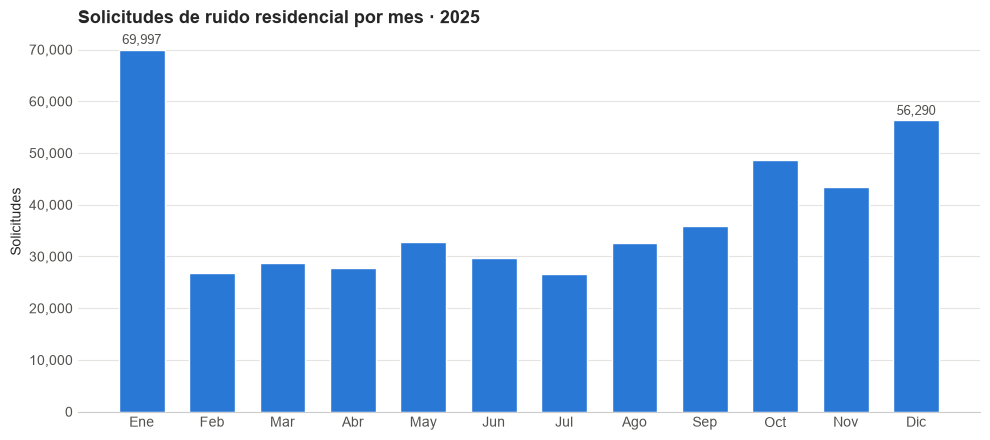

In [74]:
import matplotlib.ticker as mticker

meses = [
    "Ene",
    "Feb",
    "Mar",
    "Abr",
    "May",
    "Jun",
    "Jul",
    "Ago",
    "Sep",
    "Oct",
    "Nov",
    "Dic",
]

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.bar(meses, por_mes["total_filas"], color="#2a78d6", width=0.65)

# Etiquetas solo en los meses que se comentan en el texto
for mes in ["Ene", "Dic"]:
    i = meses.index(mes)
    valor = por_mes["total_filas"].iloc[i]
    ax.annotate(
        f"{valor:,}",
        (i, valor),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#52514e",
    )

ax.set_title(
    "Solicitudes de ruido residencial por mes · 2025",
    loc="left",
    fontsize=13,
    fontweight="bold",
)
ax.set_ylabel("Solicitudes")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

# Ejes y cuadrícula discretos: los datos son lo que destaca
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.tick_params(axis="both", length=0, labelcolor="#52514e")
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "3.1-solicitudes-por-mes.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Solicitudes por distrito

In [75]:
por_distrito = conn.sql("""
    SELECT
        borough,
        COUNT(*) AS requests,
        ROUND(COUNT(*) / SUM(COUNT(*)) OVER () * 100, 1) AS pct_of_total
    FROM df
    GROUP BY borough
    ORDER BY requests DESC
""").df()

por_distrito

,borough,requests,pct_of_total
0,BRONX,206175,44.9
1,BROOKLYN,103358,22.5
2,QUEENS,74269,16.2
3,MANHATTAN,65146,14.2
4,STATEN ISLAND,10268,2.2


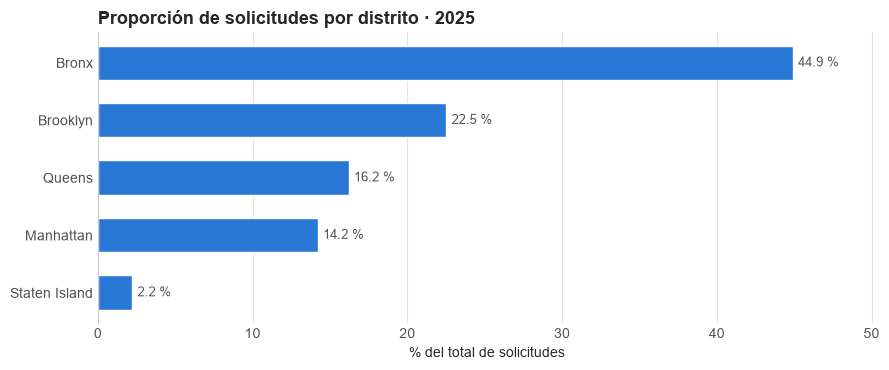

In [76]:
datos = por_distrito.sort_values(
    "pct_of_total"
)  # de menor a mayor: barh dibuja el primero abajo

fig, ax = plt.subplots(figsize=(9, 3.8))

ax.barh(
    datos["borough"].str.title(), datos["pct_of_total"], color="#2a78d6", height=0.6
)

# El valor al final de cada barra: son solo 5, se leen sin saturar
for i, valor in enumerate(datos["pct_of_total"]):
    ax.annotate(
        f"{valor:.1f} %",
        (valor, i),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color="#52514e",
    )

ax.set_title(
    "Proporción de solicitudes por distrito · 2025",
    loc="left",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("% del total de solicitudes")
ax.set_xlim(0, datos["pct_of_total"].max() * 1.12)  # espacio para las etiquetas

ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.tick_params(axis="both", length=0, labelcolor="#52514e")
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "3.2-proporcion-por-distrito.png", dpi=150, bbox_inches="tight"
)
plt.show()

**Nota:** el Bronx concentra el 44.9 % de las solicitudes del año (206.175), el doble que Brooklyn (22.5 %). Sin embargo, tiene cerca del 17 % de la población de la ciudad (Censo 2020: unos 1,47 millones de 8,8 millones; Brooklyn tiene 2,7 millones y Queens 2,4 millones). Su volumen está muy por encima de su peso poblacional. En la 3.3 se revisa si esta diferencia es pareja durante el año o se concentra en algunos meses.

### 3.3 Solicitudes por mes y distrito

In [77]:
mes_distrito = conn.sql("""
    SELECT
        created_month,
        borough,
        COUNT(*) AS requests
    FROM df
    GROUP BY created_month, borough
    ORDER BY created_month, borough
""").df()

mes_distrito.head()

,created_month,borough,requests
0,1,BRONX,51907
1,1,BROOKLYN,7086
2,1,MANHATTAN,5649
3,1,QUEENS,4715
4,1,STATEN ISLAND,640


In [78]:
tabla = mes_distrito.pivot(index="created_month", columns="borough", values="requests")
tabla

borough,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND
created_month,,,,,
1,51907,7086,5649,4715,640
2,10839,6380,4981,4022,607
3,9314,7965,5747,4951,694
4,7800,8160,5490,5563,752
5,7990,10152,5795,7809,1056
6,6682,9212,5483,7125,1134
7,6425,8143,4287,6706,999
8,7928,9969,4936,8648,1168
9,13545,9272,5087,7108,913


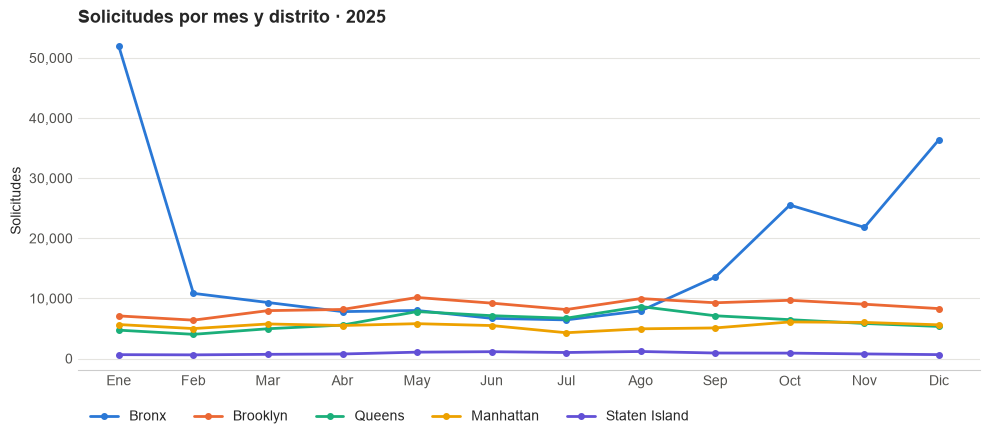

In [79]:
colores = {
    "BRONX": "#2a78d6",
    "BROOKLYN": "#eb6834",
    "QUEENS": "#1baf7a",
    "MANHATTAN": "#eda100",
    "STATEN ISLAND": "#6250d6",
}

fig, ax = plt.subplots(figsize=(10, 4.5))

for distrito, color in colores.items():
    ax.plot(
        meses,
        tabla[distrito],
        color=color,
        linewidth=2,
        marker="o",
        markersize=4,
        label=distrito.title(),
    )

ax.set_title(
    "Solicitudes por mes y distrito · 2025", loc="left", fontsize=13, fontweight="bold"
)
ax.set_ylabel("Solicitudes")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, ncols=5, loc="upper left", bbox_to_anchor=(0, -0.08))

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.tick_params(axis="both", length=0, labelcolor="#52514e")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "3.3-solicitudes-mes-distrito.png", dpi=150, bbox_inches="tight"
)
plt.show()

**Nota:**
- Todos los picos del año vienen del Bronx. En enero registra 51.907 solicitudes, unas seis veces su nivel habitual, y desde septiembre vuelve a subir (13.545) hasta 36.408 en diciembre.
- Entre febrero y agosto, el Bronx se comporta como los demás distritos: unas 8.100 solicitudes por mes en promedio, parecido a Brooklyn (8.600). En esos meses tiene el 28 % del total, no el 45 %.
- Los demás distritos se mantienen estables todo el año (Brooklyn entre 6.400 y 10.200 por mes, Queens entre 4.000 y 8.600, Manhattan entre 4.300 y 6.100 y Staten Island por debajo de 1.200), sin picos en enero ni en el último trimestre.
- Enero y septiembre–diciembre suman 149.197 de las 206.175 solicitudes del Bronx (72 %). Su 44.9 % del año no refleja un nivel alto constante, sino estos dos periodos.
- Siguiente paso (3.4): un análisis más granular del Bronx en esos meses (días, ubicaciones, precintos, tipo de ruido, canal y tiempo de cierre) para identificar la causa.

### 3.4 Investigación: volumen del Bronx en enero y septiembre–diciembre
Determinar qué explica el volumen del Bronx en esos meses: si se concentra en pocos días, en pocas ubicaciones o precintos, en algún tipo de ruido o canal, o si tiene un patrón de cierre distinto. Decidir cómo se trata en el análisis y en el cálculo del umbral.

In [80]:
bronx = df[df["borough"] == "BRONX"].copy()

meses_pico = [1, 9, 10, 11, 12]

bronx["periodo"] = (
    bronx["created_month"].isin(meses_pico).map({True: "Pico", False: "Normal"})
)

bronx.periodo.value_counts()

periodo
Pico      149197
Normal     56978
Name: count, dtype: int64

In [81]:
por_dia = conn.sql("""
    SELECT
        CAST(created_date AS DATE) AS dia,
        COUNT(*) AS requests
    FROM bronx
    GROUP BY dia
    ORDER BY dia
""").df()

por_dia.sort_values("requests", ascending=False).head(10)

,dia,requests
4,2025-01-05,5056
1,2025-01-02,4372
9,2025-01-10,4167
11,2025-01-12,3964
5,2025-01-06,3896
10,2025-01-11,3837
0,2025-01-01,3562
12,2025-01-13,3232
8,2025-01-09,3139
3,2025-01-04,3104


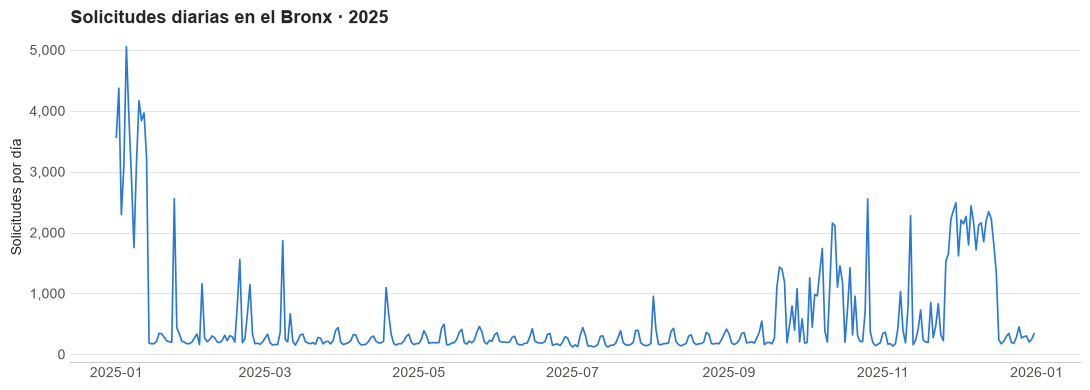

In [82]:
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(por_dia["dia"], por_dia["requests"], color="#2a78d6", linewidth=1.2)

ax.set_title(
    "Solicitudes diarias en el Bronx · 2025", loc="left", fontsize=13, fontweight="bold"
)
ax.set_ylabel("Solicitudes por día")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.tick_params(axis="both", length=0, labelcolor="#52514e")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "3.4-bronx-diario.png", dpi=150, bbox_inches="tight")
plt.show()

El volumen diario del Bronx tiene una base de 200–300 solicitudes y episodios bruscos muy por encima de ella: las primeras semanas de enero (de 2.000 a 5.000 por día), rachas intermitentes entre septiembre y noviembre, y un bloque sostenido de unos 2.000 por día entre finales de noviembre y mediados de diciembre. Los episodios empiezan y terminan de golpe, lo que apunta a una fuente concreta más que a un aumento general del distrito.

In [83]:
zip_por_periodo = (
    bronx.groupby("periodo")["incident_zip"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .rename("pct")
    .reset_index()
)

zip_por_periodo.groupby("periodo").head()

,periodo,incident_zip,pct
0,Normal,10466,18.8
1,Normal,10456,8.1
2,Normal,10467,7.4
3,Normal,10468,6.3
4,Normal,10457,5.9
25,Pico,10466,76.1
26,Pico,10456,3.5
27,Pico,10468,2.0
28,Pico,10467,1.9
29,Pico,10457,1.6


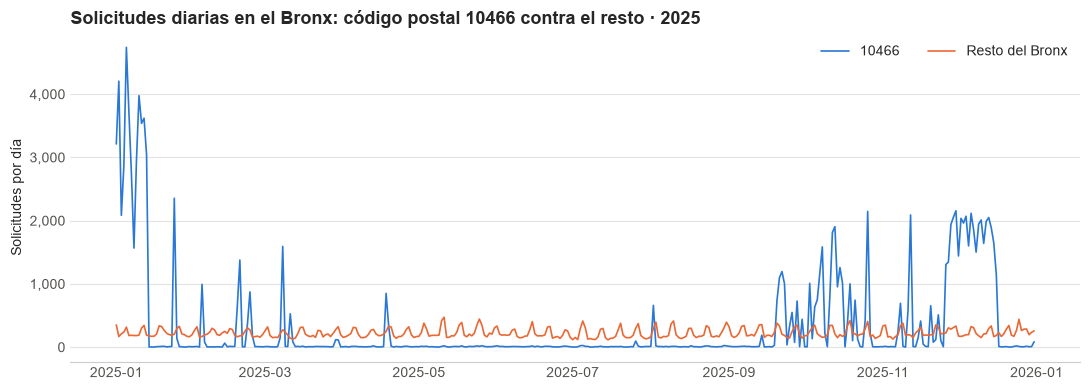

In [84]:
# Graficar vs el codigo postal
bronx["es_10466"] = bronx["incident_zip"] == "10466"

dia_zip = (
    bronx.groupby([bronx["created_date"].dt.date, "es_10466"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={True: "10466", False: "Resto del Bronx"})
)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(dia_zip.index, dia_zip["10466"], color="#2a78d6", linewidth=1.2, label="10466")
ax.plot(
    dia_zip.index,
    dia_zip["Resto del Bronx"],
    color="#eb6834",
    linewidth=1.2,
    label="Resto del Bronx",
)

ax.set_title(
    "Solicitudes diarias en el Bronx: código postal 10466 contra el resto · 2025",
    loc="left",
    fontsize=13,
    fontweight="bold",
)
ax.set_ylabel("Solicitudes por día")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, ncols=2, loc="upper right")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.tick_params(axis="both", length=0, labelcolor="#52514e")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "3.4-bronx-10466-vs-resto.png", dpi=150, bbox_inches="tight")
plt.show()

El código postal 10466 concentra el 76.1 % de las solicitudes del Bronx en los meses de pico, frente al 18.8 % en el periodo normal. Al separarlo, el resto del Bronx se mantiene estable todo el año (entre 150 y 400 solicitudes por día), y el 10466 explica todos los picos: está cerca de cero fuera de los episodios y sube a entre 1.000 y 4.700 por día durante ellos.

In [85]:
z10466 = bronx[bronx["incident_zip"] == "10466"]

ubicaciones = (
    z10466.groupby(["latitude", "longitude"])
    .size()
    .rename("requests")
    .sort_values(ascending=False)
    .reset_index()
)
ubicaciones["pct"] = (ubicaciones["requests"] / len(z10466) * 100).round(1)

print(f"Solicitudes en el 10466: {len(z10466):,}")
print(f"Ubicaciones distintas: {len(ubicaciones):,}")
ubicaciones.head(5)

Solicitudes en el 10466: 124,233
Ubicaciones distintas: 675


,latitude,longitude,requests,pct
0,40.891872,-73.860168,112490,90.5
1,40.891820,-73.860009,8307,6.7
2,40.892385,-73.859216,344,0.3
3,40.891523,-73.859066,163,0.1
4,40.892519,-73.857031,130,0.1


Dentro del 10466, una sola ubicación concentra 112.490 solicitudes (90.5 % del código postal, 54.6 % del Bronx y 24.5 % de toda la ciudad). Una segunda ubicación a unos 15 metros suma otras 8.307, probablemente el mismo edificio con otra dirección registrada.

In [86]:
lat, lon = ubicaciones.loc[0, ["latitude", "longitude"]]

df["es_punto"] = (df["latitude"] == lat) & (df["longitude"] == lon)
df["grupo"] = df["es_punto"].map({True: "Punto 10466", False: "Resto de la ciudad"})

for col in ["descriptor", "open_data_channel_type"]:
    display(pd.crosstab(df[col], df["grupo"], normalize="columns").mul(100).round(1))

grupo,Punto 10466,Resto de la ciudad
descriptor,,
Banging/Pounding,0.0,36.3
Loud Music/Party,100.0,53.1
Loud Talking,0.0,8.8
Loud Television,0.0,1.7


grupo,Punto 10466,Resto de la ciudad
open_data_channel_type,,
MOBILE,100.0,22.8
ONLINE,0.0,60.9
OTHER,0.0,0.0
PHONE,0.0,16.3
UNKNOWN,0.0,0.0


In [87]:
# Distribución por hora de creación (% de cada grupo)
pd.crosstab(df["created_hour"], df["grupo"], normalize="columns").mul(100).round(1)


grupo,Punto 10466,Resto de la ciudad
created_hour,,
0,4.6,9.0
1,3.8,6.3
2,3.2,4.0
3,3.6,2.9
4,3.5,2.1
5,3.7,1.7
6,3.6,1.7
7,3.6,1.7
8,3.5,1.8


In [88]:
# Tiempo de cierre
df.groupby("grupo")["resolution_time_hours"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
grupo,,,,,,,,
Punto 10466,112490.0,5.35,7.77,0.02,0.57,2.11,7.02,44.77
Resto de la ciudad,346726.0,2.43,4.56,0.02,0.51,1.08,2.60,167.01


In [89]:
# Las dos ubicaciones del mismo edificio (la segunda está a unos 15 m de la primera)
punto_1 = (df["latitude"] == ubicaciones.loc[0, "latitude"]) & (
    df["longitude"] == ubicaciones.loc[0, "longitude"]
)
punto_2 = (df["latitude"] == ubicaciones.loc[1, "latitude"]) & (
    df["longitude"] == ubicaciones.loc[1, "longitude"]
)
df["is_mass_reporter"] = punto_1 | punto_2

print(f"Solicitudes marcadas: {df['is_mass_reporter'].sum():,}")

# Base para las secciones 4 a 6: sin estas ubicaciones
df_analisis = df[~df["is_mass_reporter"]].copy()
print(f"Filas para el análisis: {len(df_analisis):,}")

Solicitudes marcadas: 120,797
Filas para el análisis: 338,419


**Decisión sobre el volumen del Bronx:**

Las dos ubicaciones del código postal 10466 que concentran los picos (la primera con 112.490 solicitudes y la segunda, con coordenadas casi idénticas, con 8.307) se marcan con la columna `is_mass_reporter`. No se eliminan: se conservan en los datos y se documentan como hallazgo. Se excluyen del cálculo del umbral de cierre tardío y del modelo de V1, por dos razones:

- **No se comportan como incidentes independientes.** Todas son *Loud Music/Party*, todas entran por app móvil y llegan repartidas de forma pareja durante las 24 horas, a diferencia del resto de la ciudad, donde las quejas se concentran de noche. En los días más altos, el 10466 supera las 4.000 solicitudes diarias (más de 2 por minuto). El patrón corresponde a una fuente que reporta de forma repetida, más que a quejas distintas.
- **El objetivo del modelo es predecir si una solicitud cierra tarde.** Si se mantienen, una sola ubicación tendría un peso enorme en el entrenamiento. Además, sus picos caen en enero (entrenamiento) y en septiembre–diciembre (validación y prueba), así que su peso sería distinto en cada partición, y el modelo se entrenaría y evaluaría en buena parte sobre un solo edificio.

Las secciones 4 a 6 usan `df_analisis`, que excluye estas ubicaciones.

**Hallazgos:**

- El volumen de febrero a agosto es estable (entre 26.000 y 33.000 solicitudes por mes); enero y el último trimestre están muy por encima.
- El Bronx concentra el 44.9 % de las solicitudes del año, aunque tiene cerca del 17 % de la población de la ciudad. Entre febrero y agosto su peso baja al 28 % y se comporta como Brooklyn.
- Todos los picos vienen del Bronx, y dentro del Bronx, del código postal 10466: el 76.1 % de las solicitudes en los meses de pico, frente al 18.8 % en el periodo normal. Sin ese código postal, el resto del Bronx se mantiene estable todo el año (entre 150 y 400 solicitudes por día).
- Fuera de los episodios, el 10466 está casi en cero: no es un código postal con un nivel alto constante, sino uno que se enciende y se apaga.
- Dentro del 10466, una sola ubicación concentra 112.490 solicitudes (90.5 % del código postal) y otra, con coordenadas casi idénticas, 8.307 más. Probablemente es el mismo edificio.
- Esas solicitudes no siguen el patrón del resto de la ciudad: llegan parejas las 24 horas, todas por app móvil y todas del mismo tipo de ruido.
- Es el mismo código postal que concentró los cierres en menos de 1 minuto de la regla 2.7.
- Decisión: estas ubicaciones se marcan y se excluyen del umbral y del modelo de V1. Las secciones 4 a 6 trabajan sin ellas.

## 4. Distribución del tiempo de cierre
Caracterizar la forma de la distribución y sus colas con los datos limpios.

### 4.1 Medidas de localización y dispersión
Media, mediana, desviación estándar, IQR, P90, P95 y P99.

In [90]:
medidas = conn.sql("""
    SELECT 
         COUNT(*) AS total_filas,
         AVG(resolution_time_hours) AS media,
         MEDIAN(resolution_time_hours) AS mediana,
         STDDEV(resolution_time_hours) AS desviacion_estandar,
         QUANTILE_CONT(resolution_time_hours, 0.25) AS p25,
         QUANTILE_CONT(resolution_time_hours, 0.75) AS p75,
         QUANTILE_CONT(resolution_time_hours, 0.90) AS p90,
         QUANTILE_CONT(resolution_time_hours, 0.95) AS p95,
         QUANTILE_CONT(resolution_time_hours, 0.99) AS p99
    FROM df_analisis
""").df()

medidas["iqr"] = medidas["p75"] - medidas["p25"]
medidas.round(2).T

,0
total_filas,338419.00
media,2.34
mediana,1.06
desviacion_estandar,4.49
p25,0.50
p75,2.52
p90,5.37
p95,8.29
p99,18.40
iqr,2.02


In [91]:
medidas_original = conn.sql("""
    SELECT 
         COUNT(*) AS total_filas,
         AVG(resolution_time_hours) AS media,
         MEDIAN(resolution_time_hours) AS mediana,
         STDDEV(resolution_time_hours) AS desviacion_estandar,
         QUANTILE_CONT(resolution_time_hours, 0.25) AS p25,
         QUANTILE_CONT(resolution_time_hours, 0.75) AS p75,
         QUANTILE_CONT(resolution_time_hours, 0.90) AS p90,
         QUANTILE_CONT(resolution_time_hours, 0.95) AS p95,
         QUANTILE_CONT(resolution_time_hours, 0.99) AS p99
    FROM df
""").df()

medidas_original["iqr"] = medidas_original["p75"] - medidas_original["p25"]
medidas_original.round(2).T

,0
total_filas,459216.00
media,3.15
mediana,1.22
desviacion_estandar,5.66
p25,0.51
p75,3.24
p90,8.09
p95,12.67
p99,29.63
iqr,2.73


Al incluir las ubicaciones marcadas en la 3.4, las medidas de la parte baja casi no cambian (P25 de 0.50 a 0.51 h; mediana de 1.06 a 1.22 h), pero la parte alta sube con fuerza: el P75 de 2.52 a 3.24 h (+29 %), el P90 de 5.37 a 8.09 h (+51 %) y el P99 de 18.4 a 29.6 h (+61 %). Esas solicitudes no son extremas, pero sí más lentas que el resto, y como son una cuarta parte de las filas, desplazan toda la mitad superior de la distribución. Como el umbral de cierre tardío se define con el P75, su exclusión se revisa en la 6.4.

### 4.2 Forma de la distribución

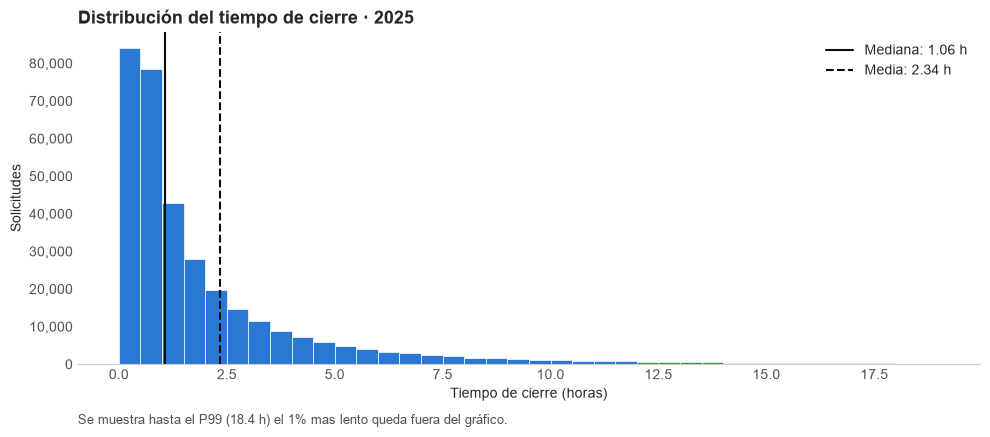

In [92]:
horas = df_analisis["resolution_time_hours"]
mediana = horas.median()
media = horas.mean()
p99 = horas.quantile(0.99)

# barras de 30 min desde el 0 hasta el P99
bins = np.arange(0, np.ceil(p99) + 0.5, 0.5)

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.hist(
    horas[horas <= p99], bins=bins, color="#2a78d6", edgecolor="white", linewidth=0.5
)

ax.axvline(
    mediana,
    color="#0b0b0b",
    linestyle="-",
    linewidth=1.5,
    label=f"Mediana: {mediana:.2f} h",
)
ax.axvline(
    media, color="#0b0b0b", linestyle="--", linewidth=1.5, label=f"Media: {media:.2f} h"
)

ax.set_title(
    "Distribución del tiempo de cierre · 2025",
    loc="left",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Tiempo de cierre (horas)")
ax.set_ylabel("Solicitudes")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, loc="upper right")

# Aclaración del recorte, debajo del gráfico

ax.text(
    0,
    -0.18,
    f"Se muestra hasta el P99 ({p99:.1f} h) el 1% mas lento queda fuera del gráfico.",
    transform=ax.transAxes,
    fontsize=9,
    color="#52514e",
)


ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="both", length=0, labelcolor="#52514e")
ax.set_axisbelow(True)


plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "4.2-distribucion-tiempo-cierre.png", dpi=150, bbox_inches="tight"
)
plt.show()

El histograma confirma el sesgo a la derecha. El valor más frecuente está en la primera media hora, y casi la mitad de las solicitudes cierra en menos de 1 hora; desde ahí la frecuencia cae de forma suave y continua, sin escalones ni segundos picos, hasta una cola larga y delgada. El orden moda < mediana (1.06 h) < media (2.34 h) es el patrón esperado en una distribución sesgada a la derecha.

### 4.3 Colas
Proporción de solicitudes que cierran en más de 12, 24 y 72 horas.

In [94]:
colas = [12, 24, 72]

for cola in colas:
    n = (horas > cola).sum()
    print(f"Solicitudes con tiempo de cierre > {cola} h: {n:,} ({n / len(horas):.2%})")

Solicitudes con tiempo de cierre > 12 h: 8,311 (2.46%)
Solicitudes con tiempo de cierre > 24 h: 1,901 (0.56%)
Solicitudes con tiempo de cierre > 72 h: 180 (0.05%)


**Hallazgos:**

- La distribución del tiempo de cierre está sesgada a la derecha: la media (2.34 h) es más del doble de la mediana (1.06 h), y el valor más frecuente está en la primera media hora.
- Casi la mitad de las solicitudes cierra en menos de 1 hora; la mitad central lo hace entre 0.5 y 2.52 h (IQR de 2.02 h).
- La cola es larga pero muy delgada: el 97.5 % cierra en menos de 12 horas, el 99.4 % en menos de un día y solo 180 solicitudes (0.05 %) pasan de 3 días.
- La desviación estándar (4.49 h) está inflada por la cola; para describir la dispersión se usa el IQR.
- Las ubicaciones marcadas en la 3.4 no cambian la parte baja de la distribución, pero sí desplazan la parte alta (P75 +29 %, P90 +51 %, P99 +61 %), porque sus solicitudes son más lentas que el resto.

## 5. Diferencias por segmento
Para cada segmento: cantidad de solicitudes, mediana, P75 y P90 del tiempo de cierre, y un gráfico comparativo.

### 5.1 Por distrito

### 5.2 Por tipo de ruido (`descriptor`)

### 5.3 Por hora del día y día de la semana

### 5.4 Ranking de precintos
Los cinco precintos con mayor mediana de tiempo de cierre dentro de cada distrito, considerando solo precintos con un volumen mínimo definido y justificado en el análisis.

**Hallazgos:**

- 
- 

## 6. Partición y umbral de cierre tardío

### 6.1 Partición temporal
Asignar cada solicitud a entrenamiento, validación o prueba y reportar el tamaño de cada partición.

### 6.2 Umbral de cierre tardío
P75 del tiempo de cierre en entrenamiento (enero–agosto), redondeado a la media hora.

### 6.3 Proporción de cierres tardíos por partición

### 6.4 Sensibilidad del umbral
Comparar el P75 de entrenamiento con y sin el bloque identificado en la sección 3.4, y justificar el valor adoptado.

**Definiciones adoptadas para V1** (se copian al README):

| Concepto | Valor |
| --- | --- |
| Filas de entrenamiento / validación / prueba | |
| Umbral de cierre tardío | h |
| % de cierres tardíos en entrenamiento | |

## 7. Conclusiones

### Resumen
- 
- 
- 

### Decisiones para V1
- 
- 

### Limitaciones
- 
- 

### Próximos pasos
- 
- 